# 第五組：可行性分析（Feasibility Analysis）

建任何模型之前先問：**資料撐得起這個策略嗎？** 本 notebook 不訓練模型、不做預測，只檢查 `setup.yaml`
裡的假設：每個決策日有沒有足夠可交易的股票、交易成本跟價格波動比起來大不大、波動率有沒有可預測的持續性、
walk-forward 切分是否放得進樣本且沒有碰到封存期。所有計算只用**開發期**（2025-01-01 之前）。

參考：ML4T 第 6 章 6.2–6.6、課程範本 `etfs/01_feasibility_analysis`。

In [1]:
from nb_utils import *                                       # 載入共用工具（路徑、設定、配色、HAC）
style()                                                      # 套用圖表樣式
panel = pd.read_parquet(PROC / "panel.parquet")              # 讀清理後的日資料（原始價＋還原價）
panel = panel[panel.sid.isin(STK + [GOLD])]                  # 只看 15 檔股票與黃金 ETF
dev = panel[panel.date < HOLDOUT_START]                      # 開發期：封存期之前
X = CFG["execution"]; C = CFG["costs"]; PF = CFG["portfolio"]  # 執行、成本、配置設定
print(f"開發期 {dev.date.min().date()} ~ {dev.date.max().date()}，封存期 {HOLDOUT_START.date()} 起本 notebook 不讀")  # 印出期間
print(f"本金 {X['capital_twd']/1e8:.0f} 億；單檔上限＝股票部位 {PF['per_name_cap']:.0%}；訂單 ≤ 20 日均額 {X['adv_cap']:.0%}")  # 印出執行假設

開發期 2016-06-01 ~ 2024-12-31，封存期 2025-01-01 起本 notebook 不讀
本金 3 億；單檔上限＝股票部位 20%；訂單 ≤ 20 日均額 5%


## B.1 每檔上市時間與資料長度
股票池是不平衡的面板：5222、6770、8028 只從**證交所上市日**開始（之前是興櫃，沒有漲跌幅限制）。

In [2]:
lst = pd.read_csv(ROOT / "data/raw/listing_dates.csv", dtype={"sid": str})  # 證交所上市日與產業別
info = dev[dev.valid].groupby("sid").agg(first=("date", "min"), valid_days=("date", "size"))  # 每檔第一天與有效天數
info = info.join(lst.set_index("sid")[["name", "twse_industry_code"]])  # 加上名稱與產業代碼
display(info)                                                # 顯示表格

,first,valid_days,name,twse_industry_code
sid,,,,
00635U,2016-06-01,2098,NaN,NaN
2303,2016-06-01,2097,聯電,24.0
2330,2016-06-01,2098,台積電,24.0
2337,2016-06-01,2089,旺宏,24.0
2340,2016-06-01,2081,台亞,24.0
2344,2016-06-01,2098,華邦電,24.0
2371,2016-06-01,2097,大同,5.0
2408,2016-06-01,2098,南亞科,24.0
2434,2016-06-01,2033,統懋,24.0


## B.2 時點正確的流動性資格（point-in-time eligibility）
某一年能不能持有一檔股票，只看**前一年**的資料決定：前一年至少 200 個有效交易日，且平均每日成交金額
不低於門檻。門檻由策略本身推導：股票部位最大 70%，約 12 檔等權，每檔約 1,750 萬；訂單不能超過
20 日均額 5%，所以想在一天內建好部位，均額至少要 1,750 萬 ÷ 5% ≈ **3.5 億**。另列 1 億的寬鬆門檻比較。
最少需要幾檔：單檔上限 20% → 至少 **5 檔**才能把股票部位放滿。

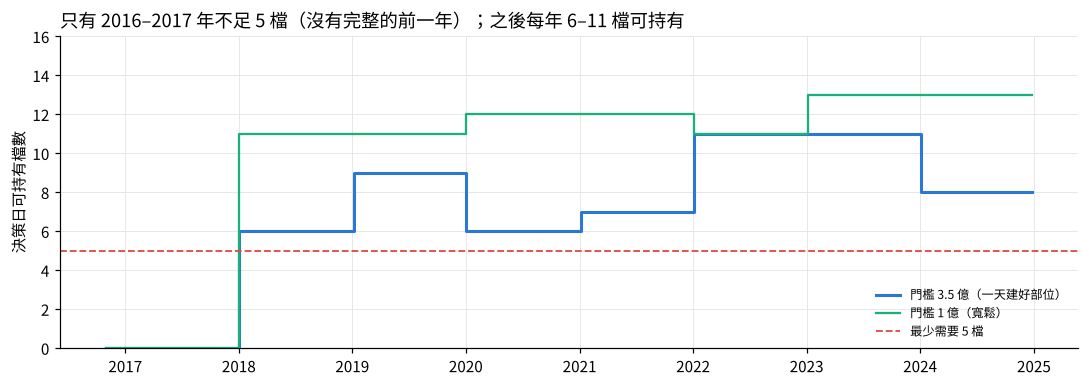

門檻 3.50 億：低於 5 檔的決策日 58/399；門檻 1 億：58/399
每年達到主門檻的股票： {2018: '2303 2330 2337 2344 2371 2408', 2019: '2303 2330 2337 2344 2371 2408 2455 3016 3532', 2020: '2303 2330 2337 2344 2408 2455', 2021: '2303 2330 2337 2344 2371 2408 3016', 2022: '2303 2330 2337 2340 2344 2371 2408 2455 3016 3532 4919', 2023: '2303 2330 2337 2340 2344 2371 2408 3532 4919 6770 8028', 2024: '2303 2330 2344 2371 2408 2455 4919 6770', 2025: '2303 2330 2344 2371 2408 2455 4919 6770 8028'}
從未達到 3.5 億門檻：['2434', '5222']；達到 1 億門檻的年度數： {'2303': 8, '2330': 8, '2337': 8, '2340': 7, '2344': 8, '2371': 8, '2408': 8, '2434': 0, '2455': 8, '3016': 6, '3532': 8, '4919': 8, '5222': 1, '6770': 3, '8028': 5}


In [3]:
pos = X["capital_twd"] * max(PF["risk_tiers"].values()) / 12  # 最高風險等級下每檔約略部位
FLOOR = pos / X["adv_cap"]                                   # 一天建好部位所需的平均成交金額
BREADTH_FLOOR = int(np.ceil(1 / PF["per_name_cap"]))         # 放滿股票部位需要的最少檔數
yr = dev.assign(year=dev.date.dt.year, amt=dev.amount.where(dev.valid))  # 加上年份與有效日成交金額
ann = yr.groupby(["sid", "year"]).agg(avg_amt=("amt", "mean"), n_days=("amt", "count")).reset_index()  # 每檔每年平均成交金額
def eligible(floor):                                         # 定義：依門檻產生「可持有年度」表
    ok = ann[(ann.n_days >= 200) & (ann.avg_amt >= floor)]   # 前一年天數與金額都達標
    return ok.assign(eligible_year=ok.year + 1)[["sid", "eligible_year"]]  # 下一年才可持有（只用過去資訊）
el_main, el_low = eligible(FLOOR), eligible(1e8)             # 主門檻與寬鬆門檻
dec = pd.read_csv(TAB / "decision_dates.csv", parse_dates=["decision_date"]).decision_date  # 決策日
dec = dec[dec < HOLDOUT_START]                               # 只看開發期
def breadth(el):                                             # 定義：每個決策日可持有幾檔股票
    s = set(map(tuple, el[el.sid.isin(STK)].values))         # （代號, 年份）集合
    return pd.Series([sum((sid, d.year) in s for sid in STK) for d in dec], index=dec)  # 逐日計數
b_main, b_low = breadth(el_main), breadth(el_low)            # 兩種門檻的檔數
fig, ax = plt.subplots(figsize=(10, 3.6))                    # 開圖
ax.step(b_main.index, b_main, where="post", color=BLUE, lw=2, label=f"門檻 {FLOOR/1e8:.1f} 億（一天建好部位）")  # 主門檻
ax.step(b_low.index, b_low, where="post", color=AQUA, lw=1.5, label="門檻 1 億（寬鬆）")  # 寬鬆門檻
ax.axhline(BREADTH_FLOOR, color=RED, ls="--", lw=1.2, label=f"最少需要 {BREADTH_FLOOR} 檔")  # 最少檔數
ax.set_ylim(0, 16); ax.set_ylabel("決策日可持有檔數"); ax.legend(frameon=False, fontsize=8, loc="lower right")  # 座標與圖例
by_year = b_main.groupby(b_main.index.year).min()          # 每年最少可持有檔數
short_years = [y for y, v in by_year.items() if v < BREADTH_FLOOR]  # 不足的年份
ax.set_title(f"只有 {short_years[0]}–{short_years[-1]} 年不足 {BREADTH_FLOOR} 檔（沒有完整的前一年）；之後每年 {by_year[by_year>=BREADTH_FLOOR].min()}–{by_year.max()} 檔可持有")  # 依數字產生標題
save(fig, "01_eligibility_breadth.png")                      # 存圖
el_main.to_csv(NB_OUT / "eligibility.csv", index=False)      # 寫出資格表（供後續 notebook 參考）
print(f"門檻 {FLOOR/1e8:.2f} 億：低於 {BREADTH_FLOOR} 檔的決策日 {int((b_main < BREADTH_FLOOR).sum())}/{len(b_main)}；"
      f"門檻 1 億：{int((b_low < BREADTH_FLOOR).sum())}/{len(b_low)}")  # 印出不足的決策日數
print("每年達到主門檻的股票：", el_main[el_main.sid.isin(STK)].groupby("eligible_year").sid.apply(lambda s: " ".join(sorted(s))).to_dict())  # 印出名單
never = sorted(set(STK) - set(el_main.sid))                  # 從未達到主門檻的股票
print(f"從未達到 {FLOOR/1e8:.1f} 億門檻：{never}；達到 1 億門檻的年度數：", el_low[el_low.sid.isin(STK)].groupby('sid').size().reindex(STK).fillna(0).astype(int).to_dict())  # 印出

## B.3 一次來回交易成本，以股價的比例表示
台股成本有三項：手續費每邊 0.1425%、證交稅（賣出時股票 0.3%、ETF 0.1%）、滑價。setup.yaml 假設滑價每邊
0.05%。但台股有**最小跳動單位**：股價 10–50 元每檔跳 0.05 元，買在賣價、賣在買價至少要付半個跳動單位。
以每檔的中位數股價換算半個跳動單位，就能檢查 5bp 的滑價假設對低價股是否太樂觀。

,median_price,half_tick_bp,assumed_slip_bp,roundtrip_assumed_bp,roundtrip_tick_bp
sid,,,,,
00635U,23.2,2.2,5.0,48.5,48.5
2455,95.6,5.2,5.0,68.5,69.0
2330,425.0,5.9,5.0,68.5,70.3
2408,64.6,7.7,5.0,68.5,74.0
2337,32.0,7.8,5.0,68.5,74.1
4919,62.9,7.9,5.0,68.5,74.4
6770,30.0,8.3,5.0,68.5,75.2
3016,58.6,8.5,5.0,68.5,75.6
8028,53.3,9.4,5.0,68.5,77.3


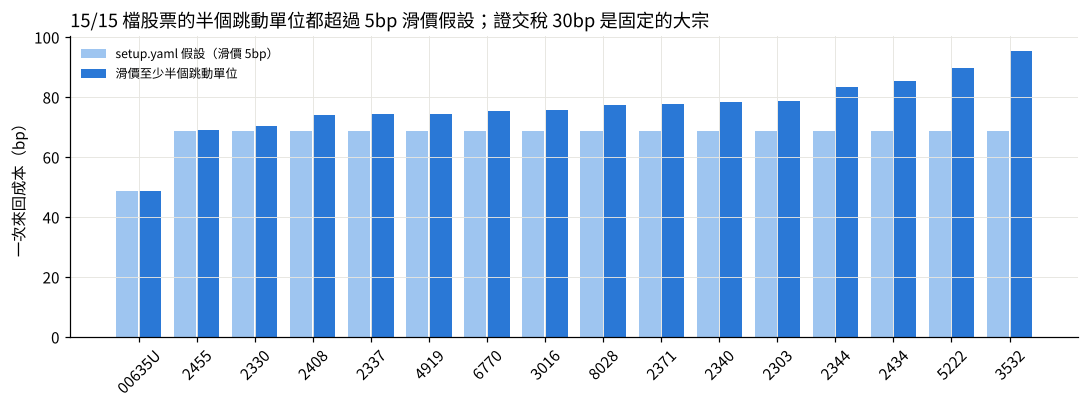

半個跳動單位超過 5bp 的：2455, 2330, 2408, 2337, 4919, 6770, 3016, 8028, 2371, 2340, 2303, 2344, 2434, 5222, 3532


In [4]:
def tick(p, etf=False):                                      # 定義：台股升降單位（2026 年規則）
    if etf: return 0.01 if p < 50 else 0.05                  # ETF：50 元以下 0.01，以上 0.05
    for lim, t in [(10, .01), (50, .05), (100, .1), (500, .5), (1000, 1)]:  # 股票分段
        if p < lim: return t                                 # 落在哪段就用該段單位
    return 5.0                                               # 1000 元以上每檔 5 元
med = dev[dev.valid].groupby("sid").close.median()           # 每檔原始收盤價中位數
cost = pd.DataFrame({"median_price": med})                   # 建表
cost["half_tick_bp"] = [tick(p, s == GOLD) / 2 / p * 1e4 for s, p in med.items()]  # 半個跳動單位（bp）
cost["assumed_slip_bp"] = C["slippage_per_side"] * 1e4       # 假設的滑價（bp）
tax = np.where(cost.index == GOLD, C["sell_tax_etf"], C["sell_tax_stock"]) * 1e4  # 賣出稅（bp）
cost["roundtrip_assumed_bp"] = 2 * C["commission_per_side"] * 1e4 + 2 * cost.assumed_slip_bp + tax  # 假設的來回成本
cost["roundtrip_tick_bp"] = 2 * C["commission_per_side"] * 1e4 + 2 * np.maximum(cost.assumed_slip_bp, cost.half_tick_bp) + tax  # 用跳動單位修正後
cost = cost.sort_values("roundtrip_tick_bp")                 # 依成本排序
display(cost.round(1))                                       # 顯示表格
fig, ax = plt.subplots(figsize=(10, 3.8))                    # 開圖
x = np.arange(len(cost))                                     # 位置
ax.bar(x - .2, cost.roundtrip_assumed_bp, .38, color="#9ec5f0", label="setup.yaml 假設（滑價 5bp）")  # 假設成本
ax.bar(x + .2, cost.roundtrip_tick_bp, .38, color=BLUE, label="滑價至少半個跳動單位")  # 修正後成本
ax.set_xticks(x); ax.set_xticklabels(cost.index, rotation=45); ax.set_ylabel("一次來回成本（bp）")  # 座標
ax.legend(frameon=False, fontsize=8); ax.set_title(f"{int((cost.half_tick_bp[cost.index != GOLD] > 5).sum())}/15 檔股票的半個跳動單位都超過 5bp 滑價假設；證交稅 30bp 是固定的大宗")  # 依數字產生標題
save(fig, "01_roundtrip_cost.png")                           # 存圖
print(f"半個跳動單位超過 5bp 的：{', '.join(cost.index[cost.half_tick_bp > 5])}")  # 印出名單

## B.4 價格變動夠不夠大，值得付成本？
每個 5 日開盤到開盤的絕對報酬，除以**該股自己**的來回成本：大於 1 代表這段變動大於交易它的成本。
只計入當年有資格（B.2 主門檻）的股票年度。這不是策略報酬（沒有方向），只是排除「變動比成本還小」的失敗情況。

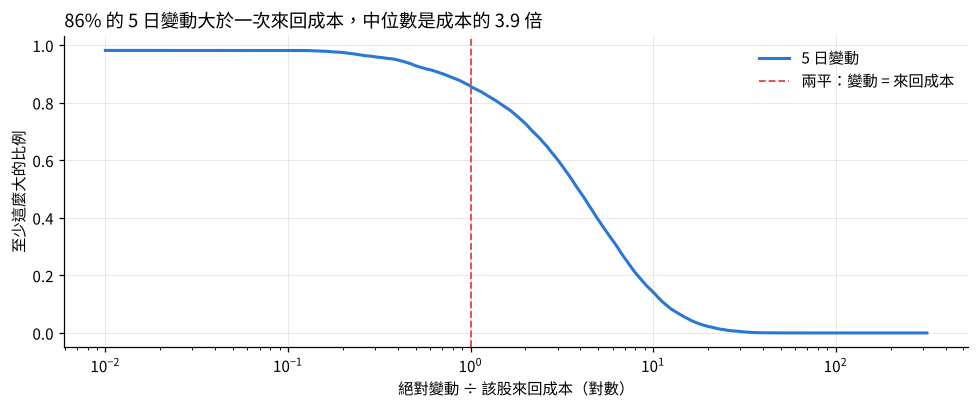

5 日絕對變動中位數 299bp，為來回成本中位數的 3.9 倍；大於成本的比例 0.858（14,065 筆）


In [5]:
el_set = set(map(tuple, el_main.values))                     # 可持有的（代號, 年份）
d5 = dev.sort_values(["sid", "date"]).copy()                 # 依股票與日期排序
d5["r5"] = d5.groupby("sid").aopen.transform(lambda s: (s.shift(-5) / s - 1).abs())  # 未來 5 日開盤報酬絕對值
d5 = d5[[(s, d.year) in el_set for s, d in zip(d5.sid, d5.date)]].dropna(subset=["r5"])  # 只留可持有年度
d5["multiple"] = d5.r5 * 1e4 / d5.sid.map(cost.roundtrip_tick_bp)  # 變動 ÷ 自己的來回成本
xs = np.logspace(-2, 2.5, 200)                               # 橫軸：成本的倍數
fig, ax = plt.subplots(figsize=(9, 3.8))                     # 開圖
ax.plot(xs, [(d5.multiple >= v).mean() for v in xs], color=BLUE, lw=2, label="5 日變動")  # 超越曲線
ax.axvline(1, color=RED, ls="--", lw=1.2, label="兩平：變動 = 來回成本"); ax.set_xscale("log")  # 兩平線
ax.set_xlabel("絕對變動 ÷ 該股來回成本（對數）"); ax.set_ylabel("至少這麼大的比例"); ax.legend(frameon=False)  # 座標
ax.set_title(f"{(d5.multiple > 1).mean():.0%} 的 5 日變動大於一次來回成本，中位數是成本的 {d5.multiple.median():.1f} 倍")  # 依數字產生標題
save(fig, "01_exceedance.png")                               # 存圖
print(f"5 日絕對變動中位數 {d5.r5.median()*1e4:.0f}bp，為來回成本中位數的 {d5.multiple.median():.1f} 倍；"
      f"大於成本的比例 {(d5.multiple > 1).mean():.3f}（{len(d5):,} 筆）")  # 印出摘要

## B.5 波動率有沒有持續性？
每檔自己的 5 日實現波動（不重疊、決策日取樣）跟它過去幾期的相關，先在每檔**內部**算，再取平均。
對照：5 日報酬本身的自我相關。波動有持續性、報酬沒有，正是「預測波動而不預測報酬」的理由。

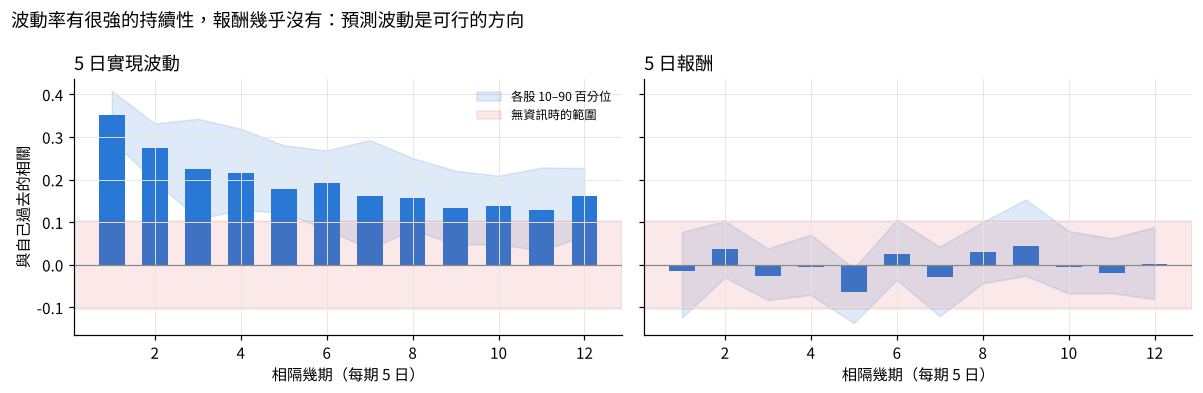

5 日波動落後 1 期平均相關 0.35、落後 4 期 0.21；5 日報酬落後 1 期 -0.01


In [6]:
s = pd.read_parquet(PROC / "samples.parquet")                # 讀樣本（含標籤）
s = s[s.sid.isin(STK)].sort_values(["sid", "date"])       # 只看股票，依時間排序
s["r5"] = s.groupby("sid").aopen.transform(lambda v: np.log(v.shift(-6) / v.shift(-1)))  # 先用每日資料算：t+1 開盤到 t+6 開盤報酬（與標籤同期間）
s = s[s.is_decision & (s.label_end < HOLDOUT_START)]         # 再只留開發期決策日（每期相隔 5 日，不重疊）
def acf_within(col, L=12):                                   # 定義：每檔內部算自我相關，再跨股票平均
    rows = []                                                # 收集
    for _, g in s.groupby("sid"):                            # 逐檔
        v = g[col].dropna().values                           # 取序列
        if len(v) < 30: continue                             # 太短略過
        rows.append([np.corrcoef(v[k:], v[:-k])[0, 1] for k in range(1, L + 1)])  # 各落後期相關
    a = np.array(rows); return a.mean(0), np.percentile(a, 10, 0), np.percentile(a, 90, 0), a.shape[0]  # 平均與 10/90 分位
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)  # 兩張並排
for ax, col, nm in zip(axs, ["y", "r5"], ["5 日實現波動", "5 日報酬"]):  # 波動與報酬
    m, lo, hi, n = acf_within(col); k = np.arange(1, 13)     # 計算
    ax.fill_between(k, lo, hi, color=BLUE, alpha=.15, label="各股 10–90 百分位"); ax.bar(k, m, color=BLUE, width=.6)  # 區間與平均
    band = 1.96 / np.sqrt(len(s) / n); ax.axhspan(-band, band, color=RED, alpha=.12, label="無資訊時的範圍")  # 無資訊區間
    ax.axhline(0, color=GREY, lw=.8); ax.set_title(f"{nm}"); ax.set_xlabel("相隔幾期（每期 5 日）")  # 標籤
axs[0].set_ylabel("與自己過去的相關"); axs[0].legend(frameon=False, fontsize=8)  # 圖例
fig.suptitle("波動率有很強的持續性，報酬幾乎沒有：預測波動是可行的方向", x=.01, ha="left", fontsize=12)  # 總標題
save(fig, "01_persistence.png")                              # 存圖
mv, _, _, _ = acf_within("y"); mr, _, _, _ = acf_within("r5")  # 數字
print(f"5 日波動落後 1 期平均相關 {mv[0]:.2f}、落後 4 期 {mv[3]:.2f}；5 日報酬落後 1 期 {mr[0]:.2f}")  # 印出

## D. Walk-forward 結構
每個 fold 訓練到某年底、驗證下一年；訓練集剔除「標籤在驗證開始前還沒結束」的樣本（purge）。
下面用斷言確認三件事：purge 至少涵蓋標籤長度、fold 數量等於設定、沒有任何驗證樣本的標籤進到封存期。

,fold,train_end_sample,val_start,val_end,purge_sessions,n_train,n_val,val_label_end_max,val_rows_resolving_in_holdout,leak_dates
0,1,2021-12-22,2022-01-01,2022-12-31,6,15429,690,2023-01-05,0,
1,2,2022-12-22,2023-01-01,2023-12-31,6,18888,690,2024-01-05,0,
2,3,2023-12-21,2024-01-01,2024-12-31,6,22324,704,2025-01-03,15,2024-12-25


【發現】驗證期有 15 筆樣本（2024-12-25）的標籤在 2025-01-01 之後才結束，讀到了封存期最初幾天的開盤價；占 2024 年驗證樣本 2.1%。正確做法是依『標籤結束日』而非『觀察日』切驗證期，05_evaluation 已依此修正。


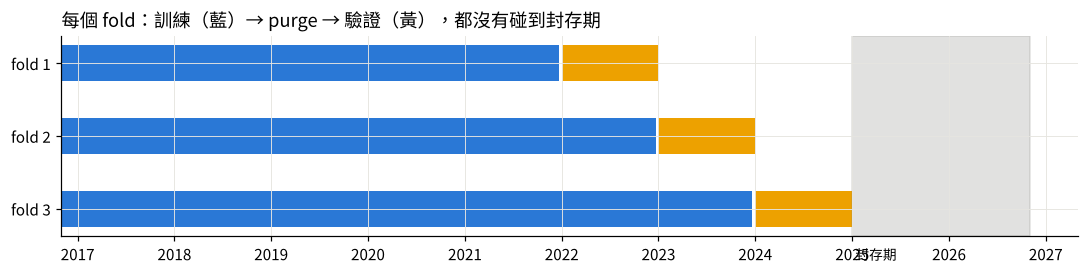

In [7]:
smp = pd.read_parquet(PROC / "samples.parquet")              # 全部樣本
cal = pd.DatetimeIndex(sorted(panel.date.unique()))          # 交易日曆
rows = []                                                    # 收集
for k, fd in enumerate(FOLDS):                               # 逐一 fold
    vs, ve = pd.Timestamp(fd["valid"][0]), pd.Timestamp(fd["valid"][1])  # 驗證起訖
    tr = smp[smp.sid.isin(STK) & smp.eligible & smp.y.notna() & (smp.label_end < vs) & (smp.date >= CFG["data"]["study_start"])]  # 訓練樣本（含 purge）
    last_tr = tr.date.max(); gap = int(((cal > last_tr) & (cal < cal[cal >= vs][0])).sum())  # 最後訓練日到驗證首日間隔幾個交易日
    va = smp[smp.sid.isin(STK) & smp.is_decision & smp.eligible & smp.y.notna() & (smp.date >= vs) & (smp.date <= ve)]  # 驗證樣本
    leak = va[va.label_end >= HOLDOUT_START]                  # 標籤在封存期才結束的驗證樣本
    rows.append({"fold": k + 1, "train_end_sample": last_tr.date(), "val_start": vs.date(), "val_end": ve.date(),
                 "purge_sessions": gap, "n_train": len(tr), "n_val": len(va), "val_label_end_max": va.label_end.max().date(),
                 "val_rows_resolving_in_holdout": len(leak), "leak_dates": ", ".join(sorted({str(d.date()) for d in leak.date}))})  # 記錄
folds = pd.DataFrame(rows); display(folds)                   # 顯示
assert len(folds) == len(FOLDS), "fold 數量與 setup.yaml 不同"  # 斷言 1
assert (folds.purge_sessions >= H).all(), "purge 間隔小於標籤長度"  # 斷言 2
n_leak = int(folds.val_rows_resolving_in_holdout.sum())      # 斷言 3 改為報告：觸及封存期的驗證樣本數
print(f"【發現】驗證期有 {n_leak} 筆樣本（{folds.leak_dates.iloc[-1]}）的標籤在 {HOLDOUT_START.date()} 之後才結束，"
      f"讀到了封存期最初幾天的開盤價；占 2024 年驗證樣本 {n_leak / folds.n_val.iloc[-1]:.1%}。"
      "正確做法是依『標籤結束日』而非『觀察日』切驗證期，05_evaluation 已依此修正。")  # 印出發現與修正方式
fig, ax = plt.subplots(figsize=(10, 2.6))                    # 時間軸圖
for i, r in folds.iterrows():                                # 逐一 fold
    y0 = len(folds) - i                                      # 縱向位置
    ax.barh(y0, pd.Timestamp(r.train_end_sample) - pd.Timestamp("2016-11-01"), left=pd.Timestamp("2016-11-01"), color=BLUE, height=.5)  # 訓練
    ax.barh(y0, pd.Timestamp(r.val_end) - pd.Timestamp(r.val_start), left=pd.Timestamp(r.val_start), color=YELLOW, height=.5)  # 驗證
ax.axvspan(HOLDOUT_START, pd.Timestamp("2026-11-01"), color=GREY, alpha=.25); ax.text(HOLDOUT_START, .3, " 封存期", fontsize=9)  # 封存期
ax.set_yticks(range(1, len(folds) + 1)); ax.set_yticklabels([f"fold {k}" for k in range(len(folds), 0, -1)])  # 標籤
ax.set_title("每個 fold：訓練（藍）→ purge → 驗證（黃），都沒有碰到封存期"); save(fig, "01_folds.png")  # 標題與存圖

## F. 證據與設定對照
| 設定 | 證據 | 什麼情況下應該改 |
|---|---|---|
| 股票池資格 | B.2 每個決策日可持有檔數 | 可持有檔數低於 5 檔的期間太長 |
| 每週決策 | B.4 變動 vs 成本、B.5 波動持續性 | 變動不再大於成本，或波動不再有持續性 |
| 滑價假設 5bp | B.3 每檔半個跳動單位 | 低價股的跳動單位成本明顯高於 5bp |
| 3 個驗證 fold | D 的斷言 | fold 放不進開發期，或碰到封存期 |

**已知限制**：15 檔是今天還存在的名單（事後選股）；資格門檻一年只算一次；跳動單位只是成本下限，
沒有真實買賣價差資料。